# Example: The Thermal Minority Game
In this example, we simulate the minority game, an agent-based model in which an odd number of agents decide to buy or sell each round and the agents on the minority side win. Each agent chooses among a few fixed policies, and in the thermal version it makes that choice with Boltzmann probabilities set by a temperature.

> __Learning Objectives:__
>
> By the end of this example, you should be able to:
> * __Simulate one minority game:__ We simulate one minority game, plot the attendance, compute the volatility of the attendance per agent, and let the attendance move a price whose growth rates we check for the stylized facts.
> * __Map the phase diagram:__ The volatility per agent depends on the number of possible histories for each agent. We vary the number of agents at a fixed memory and identify the crowded phase, the minimum near the critical value, and the dilute phase.
> * __Measure the effect of temperature:__ The temperature sets how strongly an agent favors its best-scoring policy. We vary the temperature in the crowded phase and compare the volatility with that of the greedy game and of random policy choice.

We compare every volatility with the value for agents who flip fair coins, which is one per agent.

Let's get started!
___

## Setup, Data, and Prerequisites
First, we set up the computational environment by including the `Include.jl` file and loading any needed resources.

> __Include:__ The [`include(...)` command](https://docs.julialang.org/en/v1/base/base/#include) evaluates the contents of the input source file, `Include.jl`, in the notebook's global scope. The `Include.jl` file sets paths, loads required external packages, etc. For additional information on functions and types used in this material, see the [Julia programming language documentation](https://docs.julialang.org/en/v1/).

Let's set up our code environment:

In [1]:
include(joinpath(@__DIR__, "Include.jl")); # include the Include.jl file

  Activating project at `~/Desktop/julia_work/CHEME-5660-CourseRepository-Fall-2026`


For additional information on functions and types used in this material, see the [Julia programming language documentation](https://docs.julialang.org/en/v1/) and the [CHEME 5660 Quantitative Finance Package documentation](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/).

### Constants
Next, let's set the constants. See the comments next to the constants for definitions, units, and permissible values.

In [2]:
# the minority game -
m = 6; # memory: the number of past minority actions every agent sees
P = 2^m; # number of possible histories (information states)
J = 2; # number of policies each agent holds
N_crowded = 641; # number of agents in the crowded game of Tasks 1 and 3 (odd, so the attendance is never zero); α = P/N ≈ 0.1

# the simulation -
number_of_rounds = 10_000; # rounds we record in every game, after the burn-in
burn_in = 2_000; # rounds we play first and discard, so the scores move away from their starting value of zero
number_of_seeds = 3; # independent games at each setting in Tasks 2 and 3
random_seed = 5660; # fix the random numbers, so every run gives the same games
α_c = 0.3374; # critical value of α for J = 2 and very many agents (Challet, Marsili, and Zecchina, 2000)

# the price (instructor's extension) -
m_near = 8; # memory of the comparison game in Task 1: P = 2^8 = 256 histories, so α = 256/641 ≈ 0.40, near α_c
λ = 1_000.0; # liquidity: the attendance (number of agents) that moves the log price by one
σ_S = 0.03; # annualized volatility of the price noise (1/√yr); the noise added in one round has standard deviation σ_S√Δt
S₀ = 1.0; # price at the start of the first recorded round, t = 0 (normalized, dimensionless)
price_window = 500; # number of recorded rounds in the price plot
noise_model = :normal; # distribution of the standardized noise Z: :normal or :studentt (both with mean 0 and variance 1)
ν = 5.0; # degrees of freedom of the Student-t noise, used when noise_model = :studentt (must be > 4, so the kurtosis is finite)
Δt = 1/252; # length of one round (years), taking one round as one trading day
lags = [1, 5, 20]; # lags (rounds) at which we report autocorrelations
buy_probability = 0.5; # probability b that a policy entry is buy (+1) in Task 1's games; 0.5 is the standard game

___

## Task 1: Simulate One Round of the Thermal Minority Game
In this task, we simulate one minority game with `N_crowded` agents at temperature $T=0$, where every agent uses its best-scoring policy. We measure how far the attendance moves from zero, and then we let the attendance move a price.

> __One round of the game:__
> * __Information:__ Every agent sees the same history $\mu_{t}$, the last $m$ minority actions. There are $P=2^{m}$ possible histories.
> * __Policies:__ Agent $i$ holds $J$ policies, fixed tables drawn at random when we build the game. Policy $\pi_{ij}$ gives an action $\pi_{ij}(\mu)$, buy ($+1$) or sell ($-1$), for each history $\mu$.
> * __Attendance:__ The actions sum to the attendance $A_{t}=\sum_{i=1}^{N}a_{i,t}$, which is never zero because $N$ is odd. The minority side, $-\text{sign}\,A_{t}$, wins and becomes the newest entry in the history.
> * __Scores:__ Every policy, used or not, gets the new score $U_{ij,t+1}=U_{ij,t}-\pi_{ij}(\mu_{t})A_{t}/P$. A policy that would have put its agent in the minority gains score, and one that would have put it in the majority loses score.

We measure the volatility of the attendance per agent, $\sigma_{A}^{2}/N=\langle A^{2}\rangle/N$, the average of $A_{t}^{2}$ over the recorded rounds divided by $N$. If every agent flipped a fair coin, $A_{t}$ would have mean zero and variance $N$, which gives $\sigma_{A}^{2}/N=1$. Values above 1 mean that more agents end up on the same side than with coin flips, and values below 1 mean a more even split.

__Simulate the game__: [The build(...) function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/abm/#VLQuantitativeFinancePackage.build-Tuple{Type{MyThermalMinorityGameModel},%20NamedTuple}) draws the policies of every agent at random and returns a `MyThermalMinorityGameModel`, and [the solve(...) function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/abm/#VLQuantitativeFinancePackage.solve-Tuple{MyThermalMinorityGameModel}) plays the game. In the code below:
* We pass the number of agents, the memory `m`, the number of policies `J`, the temperature, and a random number generator `rng` to `build(...)`.
* `solve(...)` first plays `burn_in` rounds and discards them, then records `number_of_rounds` rounds.
* The result `game::NamedTuple` holds the attendance `attendance::Vector{Int}`, the history of each round `information::Vector{Int}`, the volatility per agent `volatility_per_agent::Float64`, the number of histories per agent `alpha::Float64` ($\alpha=P/N$), and the final scores `final_scores::Array{Float64,2}`, one row per agent and one column per policy.

Let's simulate the game:

In [3]:
game = let

    # initialize: a random number generator with a fixed seed, so every run gives the same game -
    rng = MersenneTwister(random_seed);

    # build the game: draw J random policies for each of the N agents -
    model = build(MyThermalMinorityGameModel, (
        N = N_crowded, # number of agents (odd)
        m = m, # memory: the number of past minority actions in the history
        J = J, # policies per agent
        temperature = 0.0, # T = 0: every agent uses its best-scoring policy
        buy_probability = buy_probability, # probability that a policy entry is buy (+1)
        rng = rng # random number generator for the policies
    ));

    # play the game: discard the burn-in rounds, then record number_of_rounds rounds -
    result = solve(model; number_of_rounds = number_of_rounds, burn_in = burn_in, rng = rng);

    # checks: one attendance per recorded round, and A_t is odd, so never zero -
    @assert length(result.attendance) == number_of_rounds "one attendance per recorded round"
    @assert all(isodd, result.attendance) "with an odd number of agents, the attendance is odd"

    # return -
    result
end;

Let's put the size of the game and its volatility per agent in a table:

In [4]:
let

    # build the table: the size of the game and the volatility per agent -
    df = DataFrame(
        quantity = ["number of agents N", "memory m", "number of histories P = 2^m", "histories per agent α = P/N", "volatility per agent σ_A²/N"],
        value = [string(N_crowded), string(m), string(P), string(round(game.alpha, digits = 4)), string(round(game.volatility_per_agent, digits = 3))]
    );

    # show the table -
    pretty_table(df; column_labels = ["quantity", "value"], alignment = [:l, :r],
        table_format = TextTableFormat(borders = text_table_borders__compact), fit_table_in_display_horizontally = false);
end

 ----------------------------- --------
  quantity                       value 
 ----------------------------- --------
  number of agents N               641
  memory m                           6
  number of histories P = 2^m       64
  histories per agent α = P/N   0.0998
  volatility per agent σ_A²/N    2.804
 ----------------------------- --------


> __What do we see?__ The volatility per agent is well above 1, the value for coin flips. With many more agents than histories, the attendance moves much farther from zero than it would if every agent flipped a coin.

`Unhide` the code block below to see how we plotted the attendance for the first 200 recorded rounds. The dashed lines at $\pm\sqrt{N}$ mark one standard deviation of the attendance for coin flips.

How does the attendance move from round to round?

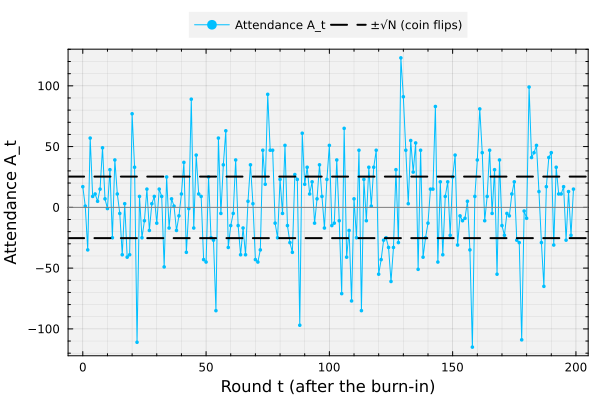

In [5]:
let

    # initialize: the first 200 recorded rounds -
    window = 0:199; # rounds t to plot
    A = game.attendance[window .+ 1]; # attendance A_t in those rounds (Julia index t + 1)
    band = sqrt(N_crowded); # one standard deviation of the attendance for coin flips

    # plot: the attendance in each round -
    plot(window, A, lw = 1, c = :deepskyblue1, marker = :circle, ms = 2, msw = 0, label = "Attendance A_t",
        bg = "gray95", background_color_outside = "white", framestyle = :box, fg_legend = :transparent,
        xminorticks = true, yminorticks = true, minorgrid = true, legend = :outertop, legend_columns = 2)
    hline!([band, -band], lw = 2, c = :black, ls = :dash, label = "±√N (coin flips)") # one standard deviation for coin flips
    hline!([0.0], lw = 1, c = :gray, label = "") # an even split between buyers and sellers

    # labels -
    xlabel!("Round t (after the burn-in)", fontsize = 18)
    ylabel!("Attendance A_t", fontsize = 18)
end

> __What do we see?__ The attendance swings far from zero in both directions, and many rounds land outside the dashed lines, one coin-flip standard deviation from zero. Large majorities of buyers and large majorities of sellers both occur, often within a few rounds of each other.

### From the attendance to a price
The original minority game has no price. In the lecture, we added one as an instructor's extension: a market maker treats the attendance as the excess demand for the asset and moves the log price:

$$
\ln S_{t+1} = \ln S_{t} + \frac{A_{t}}{\lambda} + \sigma_{S}\sqrt{\Delta t}\,Z_{t+1}
$$

where the liquidity $\lambda$ is the attendance that moves the log price by one, and $\sigma_{S}$ is the annualized volatility of the price noise. The draw $Z_{t+1}$ has mean zero and variance one. It is standard Normal or, with `noise_model = :studentt`, a Student-t with `ν` degrees of freedom rescaled to unit variance.

Because the agents never see the price, we compute it from the attendance after the game is played, starting from $S_{0}=1$ at the first recorded round, $t=0$. Averaged over many rounds, the mean square of the one-round log price change $\ln(S_{t+1}/S_{t})$ should be close to $\sigma_{A}^{2}/\lambda^{2}+\sigma_{S}^{2}\Delta t$.

__Compare two markets__: We compare the crowded game we just played, with memory $m=6$ and $\alpha\approx 0.1$, with a second game of `N_crowded` agents that differs only in its memory, `m_near`. That game has $\alpha\approx 0.40$, near the critical value. In the code below:
* A separate random number generator `price_rng` draws one noise path $Z_{1},\dots,Z_{R}$ from the `noise_model` distribution. Because both prices use it, the two price paths differ only through their attendances.
* The result `markets::Vector{NamedTuple}` holds, for each game, its name, $\alpha$, its attendance, and its log prices $\ln S_{0},\dots,\ln S_{R}$, starting from `S₀`.

Let's compute the two prices:

In [6]:
markets = let

    # initialize: a second, separately built game with the same number of agents and settings as Task 1, except the memory -
    rng = MersenneTwister(random_seed); # same seed as Task 1
    model = build(MyThermalMinorityGameModel, (N = N_crowded, m = m_near, J = J, temperature = 0.0, buy_probability = buy_probability, rng = rng)); # P = 2^m_near histories
    near = solve(model; number_of_rounds = number_of_rounds, burn_in = burn_in, rng = rng); # play the game

    # draw one standardized noise path Z_1, ..., Z_R, shared by both prices, from its own random number generator -
    price_rng = MersenneTwister(random_seed + 1); # separate from the games
    Z = if noise_model == :normal
        randn(price_rng, number_of_rounds); # Z[t] is Z_t, the standard Normal draw added at the end of recorded round t - 1
    else
        sqrt((ν - 2)/ν) .* rand(price_rng, TDist(ν), number_of_rounds); # Student-t, rescaled to unit variance
    end

    # main loop: the market maker turns each attendance into a log price -
    results = NamedTuple[];
    for (name, result) ∈ [("crowded game, m = $(m)", game), ("near α_c, m = $(m_near)", near)]
        A = result.attendance; # attendance in each recorded round; A[t] holds A_{t-1}
        log_S = Vector{Float64}(undef, number_of_rounds + 1); # Julia index k holds ln S_{k-1}: ln S_0, ..., ln S_R
        log_S[1] = log(S₀); # starting price ln S_0
        for t ∈ 1:number_of_rounds
            log_S[t+1] = log_S[t] + A[t]/λ + σ_S*sqrt(Δt)*Z[t]; # ln S_t = ln S_{t-1} + A_{t-1}/λ + σ_S√Δt Z_t, in the Julia index
        end
        push!(results, (name = name, alpha = result.alpha, attendance = A, log_price = log_S));
    end

    # checks: a known noise model, one log price per round plus the start, and every price is finite -
    @assert noise_model ∈ (:normal, :studentt) "noise_model must be :normal or :studentt"
    @assert noise_model == :normal || ν > 4 "the Student-t noise needs ν > 4 for a finite standard deviation and kurtosis"
    @assert all(length(r.log_price) == number_of_rounds + 1 for r ∈ results) "one log price per recorded round, plus the start"
    @assert all(all(isfinite, r.log_price) for r ∈ results) "the log prices must be finite"

    # return -
    results
end;

For each market, let's compare the measured mean square of $\ln(S_{t+1}/S_{t})$ with the value $\sigma_{A}^{2}/\lambda^{2}+\sigma_{S}^{2}\Delta t$ computed from its attendance:

In [7]:
let

    # build the table: α, σ_A²/N, and the measured and predicted mean square of ln(S_{t+1}/S_t) -
    df = DataFrame(
        market = [r.name for r ∈ markets],
        alpha = [r.alpha for r ∈ markets],
        volatility = [mean(abs2, r.attendance)/N_crowded for r ∈ markets], # σ_A²/N
        measured = [mean(abs2, diff(r.log_price)) for r ∈ markets], # ⟨(ln S_{t+1} - ln S_t)²⟩ = ⟨(Δt g_{t+1})²⟩
        predicted = [mean(abs2, r.attendance)/λ^2 + σ_S^2*Δt for r ∈ markets], # σ_A²/λ² + σ_S²Δt
        rms = [sqrt(mean(abs2, diff(r.log_price))) for r ∈ markets] # typical size of a one-round move in log price
    );
    pretty_table(df; column_labels = ["market", "α = P/N", "σ_A²/N", "measured mean square", "σ_A²/λ² + σ_S²Δt", "root mean square"],
        alignment = [:l, :r, :r, :r, :r, :r],
        formatters = [fmt__printf("%.3f", [2, 3]), fmt__printf("%.2e", [4, 5]), fmt__printf("%.4f", [6])],
        table_format = TextTableFormat(borders = text_table_borders__compact), fit_table_in_display_horizontally = false);
end

 --------------------- --------- -------- ---------------------- ------------------ ------------------
  market                α = P/N   σ_A²/N   measured mean square   σ_A²/λ² + σ_S²Δt   root mean square 
 --------------------- --------- -------- ---------------------- ------------------ ------------------
  crowded game, m = 6     0.100    2.804               1.80e-03           1.80e-03             0.0425
  near α_c, m = 8         0.399    0.215               1.41e-04           1.42e-04             0.0119
 --------------------- --------- -------- ---------------------- ------------------ ------------------


> __What do we see?__ In both markets, the measured mean square of $\ln(S_{t+1}/S_{t})$ matches $\sigma_{A}^{2}/\lambda^{2}+\sigma_{S}^{2}\Delta t$ to the digits shown. With the same number of agents, liquidity, and noise, the crowded game's typical one-round move, the root mean square, is 0.0425 in log price. That is more than three times the 0.0119 of the game near the critical value.

`Unhide` the code block below to see how we plotted the price $S_{t}$ of both markets for the first `price_window` recorded rounds. Both prices start at `S₀` and share the same noise path.

How do the prices of the two markets move?

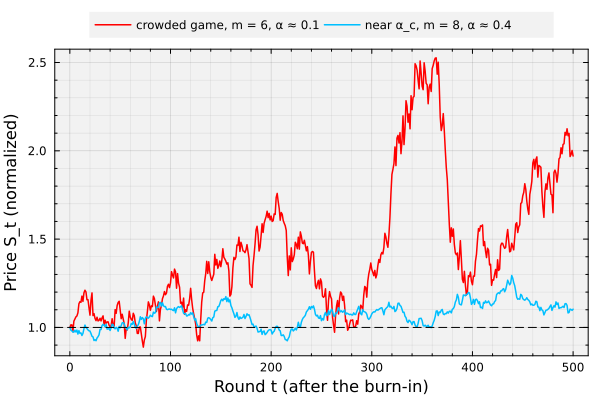

In [8]:
let

    # initialize: the first price_window + 1 prices of each market -
    window = 1:(price_window + 1); # Julia indices of S_0, ..., S_(price_window)
    colors = [:red, :deepskyblue1]; # crowded game, game near α_c

    # plot: the price S_t = exp(ln S_t) in each market -
    plot(bg = "gray95", background_color_outside = "white", framestyle = :box, fg_legend = :transparent,
        xminorticks = true, yminorticks = true, minorgrid = true, legend = :outertop, legend_columns = 2)
    for (k, r) ∈ enumerate(markets)
        plot!(window .- 1, exp.(r.log_price[window]), lw = 1.5, c = colors[k], label = "$(r.name), α ≈ $(round(r.alpha, digits = 2))")
    end
    hline!([S₀], lw = 1, c = :black, ls = :dash, label = "") # the starting price

    # labels -
    xlabel!("Round t (after the burn-in)", fontsize = 18)
    ylabel!("Price S_t (normalized)", fontsize = 18)
end

> __What do we see?__ The crowded game's price booms and busts. It climbs to about two and a half times its starting value, then loses about half of that within a few dozen rounds. The price of the game near the critical value stays within about 30% of its start.

__Growth rates and stylized facts__: If one round lasts $\Delta t$ years, the growth rate over round $t$ follows directly from the price rule:

$$
g_{t+1}=\frac{1}{\Delta t}\ln\frac{S_{t+1}}{S_{t}}=\underbrace{\frac{A_{t}}{\lambda\,\Delta t}}_{\text{agents}}+\underbrace{\frac{\sigma_{S}}{\sqrt{\Delta t}}\,Z_{t+1}}_{\text{price noise}}
$$

We measure the three stylized facts of daily growth rates for both markets: the excess kurtosis (fat tails), the autocorrelation of $g$ (little autocorrelation), and the autocorrelation of $\lvert g\rvert$ (volatility clustering). Multiplying the one-round log price changes by the constant $1/\Delta t$ does not change their excess kurtosis or their autocorrelations. In the code below:
* `excess_kurtosis(...)` is the fourth moment of the standardized series minus 3, which is zero for a Normal distribution.
* [The stylized_facts_report(...) function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/adaptive/#VLQuantitativeFinancePackage.stylized_facts_report) returns the autocorrelations of $g$ and $\lvert g\rvert$ at `lags` and the white-noise band, the range an autocorrelation stays inside 95% of the time when there is none.

Let's compute the stylized facts:

In [9]:
# excess kurtosis: the fourth moment of the standardized series, minus 3 (zero for a Normal distribution) -
excess_kurtosis(x) = mean(((x .- mean(x)) ./ std(x, corrected = false)).^4) - 3;

In [10]:
let

    # initialize: the growth rates of each market and their stylized facts -
    growth = [(1/Δt) .* diff(r.log_price) for r ∈ markets]; # g_{t+1} = (1/Δt) ln(S_{t+1}/S_t) (1/yr)
    reports = [stylized_facts_report(g; lags = lags) for g ∈ growth]; # autocorrelations of g and |g|, white-noise band

    # build the table: one row per market -
    df = DataFrame(market = [r.name for r ∈ markets], kurtosis = [excess_kurtosis(g) for g ∈ growth]);
    for (k, l) ∈ enumerate(lags)
        df[!, "acf_g_$(l)"] = [rep.raw_acf[k] for rep ∈ reports]; # autocorrelation of g at lag l
    end
    for (k, l) ∈ enumerate(lags)
        df[!, "acf_abs_$(l)"] = [rep.absolute_acf[k] for rep ∈ reports]; # autocorrelation of |g| at lag l
    end
    df[!, "band"] = [rep.white_noise_95_band for rep ∈ reports]; # white-noise band (±)
    pretty_table(df; column_labels = ["market"; "excess kurtosis"; ["acf g, lag $(l)" for l ∈ lags]; ["acf |g|, lag $(l)" for l ∈ lags]; "band (±)"],
        alignment = [:l; fill(:r, ncol(df) - 1)], formatters = [fmt__printf("%.3f", collect(2:ncol(df)))],
        table_format = TextTableFormat(borders = text_table_borders__compact), fit_table_in_display_horizontally = false);

    # checks: one growth rate per recorded round in each market -
    @assert all(length(g) == number_of_rounds for g ∈ growth) "one growth rate per recorded round"
end

 --------------------- ----------------- -------------- -------------- --------------- ---------------- ---------------- ----------------- ----------
  market                excess kurtosis   acf g, lag 1   acf g, lag 5   acf g, lag 20   acf |g|, lag 1   acf |g|, lag 5   acf |g|, lag 20   band (±) 
 --------------------- ----------------- -------------- -------------- --------------- ---------------- ---------------- ----------------- ----------
  crowded game, m = 6             1.080         -0.001         -0.002          -0.004            0.004            0.002             0.000      0.020
  near α_c, m = 8                 0.108         -0.001         -0.010          -0.013            0.040            0.018             0.000      0.020
 --------------------- ----------------- -------------- -------------- --------------- ---------------- ---------------- ----------------- ----------


> __What do we see?__
>
> * __Fat tails:__ The crowded game's growth rates have an excess kurtosis of about 1, mild fat tails that come from the agents, because Normal noise has no excess kurtosis of its own. The growth rates of the game near the critical value have an excess kurtosis near zero, like a Normal distribution.
> * __Autocorrelation and clustering:__ In both markets, every autocorrelation of $g$ is inside the white-noise band, as for the `SPY` growth rates in the Farmer–Joshi example. Only the game near the critical value shows volatility clustering, above the band at lag 1 and inside it by lag 5, while the clustering of `SPY` lasts for weeks.

Try these changes to the constants and run this task again:
* __Fat-tailed noise:__ With `noise_model = :studentt` and `σ_S = 0.3`, the excess kurtosis of the game near the critical value rises above 2, but every autocorrelation of $\lvert g\rvert$ falls inside the band. Noise drawn independently each round can add fat tails, but it cannot by itself produce volatility clustering.
* __Biased policies:__ With `buy_probability = 0.8`, every agent whose two policies disagree switches to selling, but agents whose two policies both say buy cannot switch. The attendance in Task 1 then becomes a flat line at a positive value, and the history stops changing. The price rises by about 18% every round, a trend with no volatility from the agents.
* __A weaker bias:__ Below a buy probability of about 0.71, the agents who can sell remove most of the bias.

### Choosing a policy at a finite temperature
So far, every agent used its best-scoring policy. In the thermal game, agent $i$ instead uses policy $\pi_{ij}$ with the Boltzmann probability:

$$
p_{ij} = \frac{\exp\left(U_{ij}/T\right)}{\displaystyle\sum_{k=1}^{J}\exp\left(U_{ik}/T\right)}
$$

where $T\geq 0$ is the temperature, measured in the same units as the scores. The lecture derives this rule by maximizing the entropy of the choice probabilities for a fixed expected score.

At $T=0$ the agent always uses its best policy, and as $T\to\infty$ it picks each of its $J$ policies with probability $1/J$, whatever the scores. What matters in between is the temperature compared with the gap between the scores.

[The boltzmann_weights(...) function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/abm/#VLQuantitativeFinancePackage.boltzmann_weights) computes these probabilities. Let's apply it to the final scores of one agent whose two scores differ, at temperatures from zero to infinity, with the finite ones set to multiples of that agent's score gap $\Delta=|U_{i1}-U_{i2}|$:

In [11]:
let

    # initialize: the first agent whose two final scores differ, and its score gap -
    i = findfirst(k -> game.final_scores[k, 1] != game.final_scores[k, 2], 1:N_crowded); # agent index
    U = game.final_scores[i, :]; # final scores of agent i's policies
    Δ = abs(U[1] - U[2]); # score gap
    println("agent i = $(i): scores U = $(round.(U, digits = 2)), score gap Δ = $(round(Δ, digits = 2))");

    # compute the Boltzmann probabilities at each temperature -
    temperatures = [0.0, 0.1*Δ, Δ, 10*Δ, Inf]; # T = 0, three multiples of the score gap, and T = ∞
    probabilities = [boltzmann_weights(U, T) for T ∈ temperatures]; # one probability vector per temperature

    # build the table: one row per temperature -
    df = DataFrame(
        T_over_Δ = ["0", "0.1", "1", "10", "∞"],
        T = temperatures,
        p1 = [p[1] for p ∈ probabilities],
        p2 = [p[2] for p ∈ probabilities]
    );
    pretty_table(df; column_labels = ["T/Δ", "temperature T", "p(policy 1)", "p(policy 2)"], alignment = [:r, :r, :r, :r],
        formatters = [fmt__printf("%.2f", [2]), fmt__printf("%.4f", [3, 4])],
        table_format = TextTableFormat(borders = text_table_borders__compact), fit_table_in_display_horizontally = false);

    # checks: every row is a probability distribution -
    @assert all(p -> isapprox(sum(p), 1.0) && all(≥(0.0), p), probabilities) "each row must sum to 1"
end

agent i = 1: scores U = [-1.06, -5.91], score gap Δ = 4.84
 ----- --------------- ------------- -------------
  T/Δ   temperature T   p(policy 1)   p(policy 2) 
 ----- --------------- ------------- -------------
    0            0.00        1.0000        0.0000
  0.1            0.48        1.0000        0.0000
    1            4.84        0.7311        0.2689
   10           48.44        0.5250        0.4750
    ∞             Inf        0.5000        0.5000
 ----- --------------- ------------- -------------


> __What do we see?__ At $T=0$ and at a tenth of the score gap, the agent uses its better policy with probability 1 to four decimal places. When the temperature equals the score gap, it still uses the better policy about 73% of the time, and at ten times the gap the two probabilities are close to 1/2, the $T=\infty$ row.
>
> Because the probabilities depend only on $T/\Delta$, the probabilities of the better and the worse policy in each row are the same for any agent whose two scores differ.

Your numbers will differ if you change the constants.
___

## Task 2: Map the Phase Diagram
In this task, we hold the memory at $m=6$, which gives $P=64$ histories, and vary the number of agents $N$ to see how the volatility per agent depends on the number of histories per agent, $\alpha=P/N$. This ratio matters because every agent uses its best-scoring policy, and every score is updated with the same attendance:
* __Small $\alpha$:__ The agents far outnumber the histories. Many of them hold strongly correlated policies and switch to the same action at the same time, which moves the attendance far from zero, as we saw in Task 1.
* __Large $\alpha$:__ Each policy is a long table, and the agents' choices barely affect each other's scores.

[Challet, Marsili, and Zecchina (2000)](https://arxiv.org/pdf/cond-mat/9904392) showed that, for $J=2$ policies and very many agents, the volatility per agent has its minimum at the critical value $\alpha_{c}\approx 0.3374$. We call the region $\alpha<\alpha_{c}$ the crowded phase and the region $\alpha>\alpha_{c}$ the dilute phase.

At $\alpha_{c}$, the game goes through a phase transition. A phase transition is a sharp change in the collective behavior of a large system when a parameter crosses a critical value, as when water freezes at 0 °C.

__Sweep the number of agents__: For each $N$, we build and play `number_of_seeds` independent games at $T=0$ and record each game's volatility per agent. In the code below:
* The list `agent_counts::Vector{Int}` holds odd numbers of agents from 21 to 1,001, with extra values from 151 to 251, near $N\approx P/\alpha_{c}\approx 190$, where we expect the minimum.
* One random number generator `rng`, seeded with `random_seed`, supplies the policies and the choices in every game. Each game is different, but the whole sweep is reproducible.
* The result `phase_df::DataFrame` has one row per game: the number of agents, $\alpha$, the seed index, and $\sigma_{A}^{2}/N$.

Let's run the sweep:

In [12]:
phase_df = let

    # initialize: odd numbers of agents, denser near N ≈ P/α_c, and one random number generator for the whole sweep -
    agent_counts = [21, 41, 61, 81, 101, 121, 141, 151:10:251..., 281, 321, 401, 501, 641, 801, 1001]; # numbers of agents N (all odd)
    rng = MersenneTwister(random_seed); # reproducible sweep
    df = DataFrame(N = Int[], alpha = Float64[], seed = Int[], volatility = Float64[]); # one row per game

    # main loop: number_of_seeds games for every number of agents -
    for N ∈ agent_counts
        for k ∈ 1:number_of_seeds
            model = build(MyThermalMinorityGameModel, (N = N, m = m, J = J, temperature = 0.0, rng = rng)); # new random policies
            result = solve(model; number_of_rounds = number_of_rounds, burn_in = burn_in, rng = rng); # play the game
            push!(df, (N, result.alpha, k, result.volatility_per_agent)); # store α and σ_A²/N
        end
    end

    # checks: every number of agents is odd, and one row per game -
    @assert all(isodd, agent_counts) "the number of agents must be odd"
    @assert nrow(df) == length(agent_counts)*number_of_seeds "one row per game"

    # return -
    df
end;

For each number of agents, we average the volatility per agent over the games. Where does the smallest average fall, compared with the cited critical value?

In [13]:
phase_mean_df = let

    # initialize: the average of σ_A²/N over the games at each number of agents -
    df = combine(groupby(phase_df, [:N, :alpha], sort = true), :volatility => mean => :mean_volatility); # one row per N
    sort!(df, :alpha); # increasing α
    j = argmin(df.mean_volatility); # row with the smallest average volatility

    # show the minimum: simulated, next to the cited critical value -
    summary_df = DataFrame(
        quantity = ["α at the smallest average σ_A²/N (simulated)", "smallest average σ_A²/N (simulated)", "number of agents there", "critical value α_c (Challet, Marsili, and Zecchina)"],
        value = [string(round(df.alpha[j], digits = 4)), string(round(df.mean_volatility[j], digits = 3)), string(df.N[j]), string(α_c)]
    );
    pretty_table(summary_df; column_labels = ["quantity", "value"], alignment = [:l, :r],
        table_format = TextTableFormat(borders = text_table_borders__compact), fit_table_in_display_horizontally = false);

    # checks: one row per number of agents -
    @assert nrow(df) == length(unique(phase_df.N)) "one row per number of agents"

    # return -
    df
end;

 ----------------------------------------------------- --------
  quantity                                               value 
 ----------------------------------------------------- --------
  α at the smallest average σ_A²/N (simulated)          0.3536
  smallest average σ_A²/N (simulated)                    0.142
  number of agents there                                   181
  critical value α_c (Challet, Marsili, and Zecchina)   0.3374
 ----------------------------------------------------- --------


> __What do we see?__ The smallest average volatility in our sweep is far below 1, and it falls at a value of $\alpha$ close to the cited critical value $\alpha_{c}$. With at most about a thousand agents and three games at each $N$, we do not expect to recover $\alpha_{c}$ exactly.

`Unhide` the code block below to see how we plotted the phase diagram: the volatility per agent against $\alpha$ on log axes, one faint point per game and a line through the averages.

How does the volatility per agent depend on the number of histories per agent?

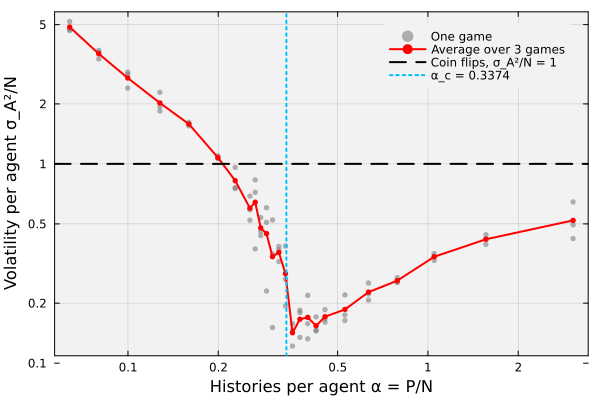

In [14]:
let

    # plot: one faint point per game, and the averages over the games -
    scatter(phase_df.alpha, phase_df.volatility, ms = 3, msw = 0, c = :gray50, alpha = 0.6, label = "One game",
        xscale = :log10, yscale = :log10,
        xticks = ([0.1, 0.2, 0.5, 1.0, 2.0], ["0.1", "0.2", "0.5", "1", "2"]), # plain tick labels on the log axes
        yticks = ([0.1, 0.2, 0.5, 1.0, 2.0, 5.0], ["0.1", "0.2", "0.5", "1", "2", "5"]),
        bg = "gray95", background_color_outside = "white", framestyle = :box, fg_legend = :transparent,
        xminorticks = true, yminorticks = true, minorgrid = true, legend = :topright)
    plot!(phase_mean_df.alpha, phase_mean_df.mean_volatility, lw = 2, c = :red, marker = :circle, ms = 3, msw = 0,
        label = "Average over $(number_of_seeds) games") # the averages
    hline!([1.0], lw = 2, c = :black, ls = :dash, label = "Coin flips, σ_A²/N = 1") # agents who flip fair coins
    vline!([α_c], lw = 2, c = :deepskyblue1, ls = :dot, label = "α_c = $(α_c)") # cited critical value

    # labels -
    xlabel!("Histories per agent α = P/N", fontsize = 18)
    ylabel!("Volatility per agent σ_A²/N", fontsize = 18)
end

> __What do we see?__
>
> * __Crowded phase:__ For the smallest values of $\alpha$, the volatility per agent is above the coin-flip line and grows as $\alpha$ falls. Here, the attendance swings farther from zero than if every agent flipped a coin.
> * __Near the critical value:__ The volatility per agent drops below the coin-flip line around $\alpha=0.2$. The games at the same $\alpha$ differ most just below $\alpha_{c}$, the dotted line, where some fall far below the average.
> * __Dilute phase:__ For $\alpha$ above the minimum, the volatility per agent rises again toward the coin-flip line, but it is still below that line at the largest $\alpha$ we tried.

Your numbers will differ if you change the constants. Try `m = 5` or `m = 7` and compare the curves plotted against $\alpha$.
___

## Task 3: Measure the Effect of Temperature
In this task, we return to the crowded game of Task 1, with `N_crowded` agents and $\alpha\approx 0.1$, and vary the temperature $T$ of the Boltzmann choice rule. At $T=0$, we have the greedy game, with a volatility per agent above 1. As $T\to\infty$, every agent picks each of its two policies with probability 1/2 every round, whatever the scores.

[Cavagna, Garrahan, Giardina, and Sherrington (1999)](https://arxiv.org/pdf/cond-mat/9903415) found that between these two limits there is a range of temperatures where the volatility falls below the value for random choice.

Because our scores are divided by $P$ (the scaling of Challet, Marsili, and Zecchina), while theirs are divided by $N$, our temperature axis is on a different scale. We read where the low-volatility range lies from our own output.

__Sweep the temperature__: For each temperature, we build and play `number_of_seeds` games with `N_crowded` agents and record each game's volatility per agent. In the code below:
* `temperatures::Vector{Float64}` runs from 0.01 to 100,000 on a log grid with two values for every factor of ten, and we also play the two limits, $T=0$ and $T=\infty$.
* As in Task 2, one random number generator `rng`, seeded with `random_seed`, supplies every game.
* The result `temperature_df::DataFrame` has one row per game: the temperature, the seed index, and $\sigma_{A}^{2}/N$.

Let's run the sweep:

In [15]:
temperature_df = let

    # initialize: a log grid of temperatures plus the two limits, and one random number generator for the whole sweep -
    temperatures = [0.0; 10.0 .^ range(-2, 5, length = 15); Inf]; # T = 0, 0.01 to 100,000, and T = ∞
    rng = MersenneTwister(random_seed); # reproducible sweep
    df = DataFrame(temperature = Float64[], seed = Int[], volatility = Float64[]); # one row per game

    # main loop: number_of_seeds games at every temperature -
    for T ∈ temperatures
        for k ∈ 1:number_of_seeds
            model = build(MyThermalMinorityGameModel, (N = N_crowded, m = m, J = J, temperature = T, rng = rng)); # new random policies
            result = solve(model; number_of_rounds = number_of_rounds, burn_in = burn_in, rng = rng); # play the game
            push!(df, (T, k, result.volatility_per_agent)); # store σ_A²/N
        end
    end

    # checks: one row per game -
    @assert nrow(df) == length(temperatures)*number_of_seeds "one row per game"

    # return -
    df
end;

Let's compare the greedy game, the smallest average volatility at a finite temperature, and random choice:

In [16]:
temperature_mean_df = let

    # initialize: the average of σ_A²/N over the games at each temperature -
    df = combine(groupby(temperature_df, :temperature, sort = true), :volatility => mean => :mean_volatility); # one row per temperature
    finite = filter(:temperature => T -> 0 < T < Inf, df); # finite, nonzero temperatures
    j = argmin(finite.mean_volatility); # finite temperature with the smallest average volatility

    # show the comparison -
    summary_df = DataFrame(
        setting = ["greedy game, T = 0", "smallest average at a finite temperature", "random choice, T = ∞"],
        temperature = [0.0, finite.temperature[j], Inf],
        mean_volatility = [only(df.mean_volatility[df.temperature .== 0.0]), finite.mean_volatility[j], only(df.mean_volatility[isinf.(df.temperature)])]
    );
    pretty_table(summary_df; column_labels = ["setting", "temperature T", "average σ_A²/N"], alignment = [:l, :r, :r],
        formatters = [fmt__printf("%.3f", [3])],
        table_format = TextTableFormat(borders = text_table_borders__compact), fit_table_in_display_horizontally = false);

    # checks: the grid has both limits -
    @assert any(==(0.0), df.temperature) && any(isinf, df.temperature) "the sweep must include T = 0 and T = ∞"

    # return -
    df
end;

 ------------------------------------------ --------------- ----------------
  setting                                    temperature T   average σ_A²/N 
 ------------------------------------------ --------------- ----------------
  greedy game, T = 0                                   0.0            2.723
  smallest average at a finite temperature           100.0            0.462
  random choice, T = ∞                                 Inf            1.081
 ------------------------------------------ --------------- ----------------


> __What do we see?__ At the best finite temperature in our grid, the average volatility per agent is far below both the greedy game and random choice. Random choice gives a volatility per agent close to 1, the coin-flip value.

`Unhide` the code block below to see how we plotted the volatility per agent against the temperature on a log axis. The horizontal lines mark the greedy game ($T=0$), random choice ($T=\infty$), and coin flips.

How does the volatility per agent change with the temperature?

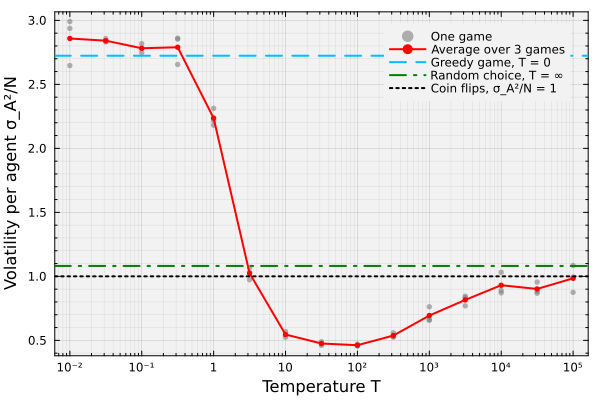

In [17]:
let

    # initialize: the finite temperatures, and the averages at the two limits -
    finite_games = filter(:temperature => T -> 0 < T < Inf, temperature_df); # games at finite, nonzero temperatures
    finite_means = filter(:temperature => T -> 0 < T < Inf, temperature_mean_df); # their averages
    greedy = only(temperature_mean_df.mean_volatility[temperature_mean_df.temperature .== 0.0]); # average σ_A²/N at T = 0
    random_choice = only(temperature_mean_df.mean_volatility[isinf.(temperature_mean_df.temperature)]); # average σ_A²/N at T = ∞

    # plot: one faint point per game, and the averages over the games -
    scatter(finite_games.temperature, finite_games.volatility, ms = 3, msw = 0, c = :gray50, alpha = 0.6, label = "One game",
        xscale = :log10, xticks = (10.0 .^ (-2:5), ["10⁻²", "10⁻¹", "1", "10", "10²", "10³", "10⁴", "10⁵"]), # one tick per factor of ten
        bg = "gray95", background_color_outside = "white", framestyle = :box, fg_legend = :transparent,
        xminorticks = true, yminorticks = true, minorgrid = true, legend = :topright)
    plot!(finite_means.temperature, finite_means.mean_volatility, lw = 2, c = :red, marker = :circle, ms = 3, msw = 0,
        label = "Average over $(number_of_seeds) games") # the averages
    hline!([greedy], lw = 2, c = :deepskyblue1, ls = :dash, label = "Greedy game, T = 0") # the T = 0 limit
    hline!([random_choice], lw = 2, c = :green, ls = :dashdot, label = "Random choice, T = ∞") # the T = ∞ limit
    hline!([1.0], lw = 2, c = :black, ls = :dot, label = "Coin flips, σ_A²/N = 1") # agents who flip fair coins

    # labels -
    xlabel!("Temperature T", fontsize = 18)
    ylabel!("Volatility per agent σ_A²/N", fontsize = 18)
end

> __What do we see?__
>
> * __Low temperatures:__ Up to about $T=0.3$, the volatility per agent stays near the greedy line. For the agent in the table in Task 1, a temperature this small compared with its score gap gives its better policy a probability close to 1.
> * __Intermediate temperatures:__ Between about $T=1$ and $T=10$, the volatility per agent drops steeply and crosses the random-choice line. From about $T=10$ to $T=1{,}000$ it stays well below both the greedy line and the random-choice line, with its smallest value near $T=100$.
> * __High temperatures:__ Above about $T=1{,}000$, the volatility per agent rises back toward the random-choice line, with some ups and downs from one temperature to the next.

Your numbers will differ if you change the constants. Try `number_of_rounds = 20_000` and see how the right end of the curve changes. Because the scores keep adding up over a game, a longer game has larger score gaps at the same temperature.
___

## Summary
In this example, we simulated the minority game, measured the volatility of the attendance per agent, mapped how it depends on the number of histories per agent, and measured how the temperature of the policy choice changes it. We also let the attendance move a price.

> __Key Takeaways:__
>
> * __A few rules produce a measurable aggregate:__ We simulated agents who each buy or sell with one of two fixed policies, scored every policy after each round, and recorded the attendance. The volatility of the attendance per agent let us compare the whole population with agents who flip coins.
>
>   When we let the attendance move a price, the crowded game moved it more than a game near the critical value. Its growth rates had mild fat tails but almost no volatility clustering.
> * __The number of histories per agent sets the volatility:__ We varied the number of agents at a fixed memory and found the crowded phase, where the volatility is above the coin-flip value, a minimum well below it near the cited critical value, and the dilute phase, where it rises toward the coin-flip value again.
>
>   The same model and rules behave differently depending only on how many agents share the histories.
> * __Temperature changes the crowded game:__ We varied the temperature of the Boltzmann choice rule at a crowded setting. Low temperatures gave the greedy game, high temperatures approached random choice, and in between the volatility fell below both limits.

The agents, the history they see, their rule for choosing a policy, the attendance, and the scores that feed the attendance back into the next choice are the five parts of an agent-based model from the lecture.
___

## Disclaimer and Risks
__This content is offered solely for training and informational purposes__. No offer or solicitation to buy or sell securities or derivative products or any investment or trading advice or strategy is made, given, or endorsed by the teaching team.

__Trading involves risk__. Carefully review your financial situation before investing in securities, futures contracts, options, or commodity interests. Past performance, whether actual or indicated by historical tests of strategies, is no guarantee of future performance or success. Trading is generally inappropriate for someone with limited resources, investment or trading experience, or a low-risk tolerance. Only risk capital that is not required for living expenses should be used.

__You are fully responsible for any investment or trading decisions you make__. Such decisions should be based solely on evaluating your financial circumstances, investment or trading objectives, risk tolerance, and liquidity needs.

___